In [ ]:
#Importando bibliotecas
import pandas as pd
import numpy as np


In [169]:
#Chamada do arquivo .csv
df_vendas = pd.read_csv(r'c:\Users\USER\Desktop\python\bd_vendas-registroVendas.csv')

In [170]:
#Pré-visualização do arquivo
df_vendas

,ID Pedido,Data Pedido,Código Loja,Produto,Qtde/Preco Unit,Pagamento
0,AX04,1/1/2023,A1500108,Carteira,23/210,Cartão de Crédito
1,AX16,1/3/2023,A1500108,FONE,22/159,Transferência/PIX
2,AX15,1/3/2023,A1500108,Malaa,"69/499,19",Cartão de Crédito
3,AX13,1/3/2023,A1500108,Mochila,"66/630,99",Cartão de Crédito
4,AX22,1/4/2023,A1500108,Boné,"37/160,99",Cartão de Crédito
...,...,...,...,...,...,...
1950,AX5406,12/31/2023,A1500107,Garrafa,"100/119,3",Transferência/PIX
1951,AX3255,12/31/2023,A1500108,Mochila,"29/630,99",Cartão de Crédito
1952,AX5407,12/31/2023,A1500107,BOLSA,80/999,Cartão de Crédito
1953,AX5401,12/31/2023,A1500107,Tênis,"184/320,19",Cartão de Crédito


In [171]:
#Tratamento dos dados usando replace
df_vendas ['Produto'] = df_vendas ['Produto'].replace({
    'FONE' : 'Fone',
    'Malaa' : 'Mala',
    'BOLSA' : 'Bolsa'
})

In [172]:
#Tratamento dos dados
#Dividindo colunas unificadas
df_vendas[['Quantidade', 'Preço Unitário']] = df_vendas['Qtde/Preco Unit'].str.split('/', expand=True)

In [173]:
#Tratamento dos dados substituindo (,) por (.)
#Após a separação das colunas unificadas, os dados das mesmas foram transformados em string (texto)
#Transformando uma string (texto) em dados numéricos novamente, usando pandas (pd.to_numeric) 
df_vendas['Preço Unitário'] = (
    df_vendas['Preço Unitário'].str.replace(',', '.', regex=False))

df_vendas['Preço Unitário'] = pd.to_numeric(
    df_vendas['Preço Unitário']
)

df_vendas['Quantidade'] = pd.to_numeric(
    df_vendas['Quantidade'])

# Convertendo a data
df_vendas['Data Pedido'] = pd.to_datetime(
    df_vendas['Data Pedido'],
    format='%m/%d/%Y',
    errors='coerce'
)

In [174]:
#Excluindo a coluna que foi  tratada
df_vendas = df_vendas.drop(columns=['Qtde/Preco Unit'])

In [175]:
#Visualização dos dados 
#Tratamento quase concluído
df_vendas

,ID Pedido,Data Pedido,Código Loja,Produto,Pagamento,Quantidade,Preço Unitário
0,AX04,2023-01-01,A1500108,Carteira,Cartão de Crédito,23,210.00
1,AX16,2023-01-03,A1500108,Fone,Transferência/PIX,22,159.00
2,AX15,2023-01-03,A1500108,Mala,Cartão de Crédito,69,499.19
3,AX13,2023-01-03,A1500108,Mochila,Cartão de Crédito,66,630.99
4,AX22,2023-01-04,A1500108,Boné,Cartão de Crédito,37,160.99
...,...,...,...,...,...,...,...
1950,AX5406,2023-12-31,A1500107,Garrafa,Transferência/PIX,100,119.30
1951,AX3255,2023-12-31,A1500108,Mochila,Cartão de Crédito,29,630.99
1952,AX5407,2023-12-31,A1500107,Bolsa,Cartão de Crédito,80,999.00
1953,AX5401,2023-12-31,A1500107,Tênis,Cartão de Crédito,184,320.19


In [176]:
#Identificando dados negativos ou iguais a zero na coluna Quantidade e Preço Unitário.
df_vendas[(df_vendas['Quantidade'] <= 0) & (df_vendas['Preço Unitário'] <= 0)]

,ID Pedido,Data Pedido,Código Loja,Produto,Pagamento,Quantidade,Preço Unitário


In [177]:
#Multiplicado colunas (Quantidade * Preço Unitário)
#Adicionando coluna de Faturamento Total
df_vendas['Faturamento Total'] = (
    df_vendas['Quantidade'] * df_vendas['Preço Unitário']
)

In [201]:
print(df_vendas.isnull().sum())

print(
    f'Registros duplicados: {df_vendas.duplicated().sum()}'
)

print(df_vendas.dtypes)

ID Pedido            0
Data Pedido          0
Código Loja          0
Produto              0
Pagamento            0
Quantidade           0
Preço Unitário       0
Faturamento Total    0
dtype: int64
Registros duplicados: 0
ID Pedido                       str
Data Pedido          datetime64[us]
Código Loja                     str
Produto                         str
Pagamento                       str
Quantidade                    int64
Preço Unitário              float64
Faturamento Total           float64
dtype: object


In [179]:
# Resumo estrutural dos dados
# Verificando se há dados nulos
df_vendas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1955 entries, 0 to 1954
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   ID Pedido          1955 non-null   str           
 1   Data Pedido        1955 non-null   datetime64[us]
 2   Código Loja        1955 non-null   str           
 3   Produto            1955 non-null   str           
 4   Pagamento          1955 non-null   str           
 5   Quantidade         1955 non-null   int64         
 6   Preço Unitário     1955 non-null   float64       
 7   Faturamento Total  1955 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 122.3 KB


In [326]:
df_vendas.head()

,ID Pedido,Data Pedido,Código Loja,Produto,Pagamento,Quantidade,Preço Unitário,Faturamento Total
0,AX04,2023-01-01,Filial 02 RJ,Carteira,Cartão de Crédito,23,210.00,4830.00
1,AX16,2023-01-03,Filial 02 RJ,Fone,Transferência/PIX,22,159.00,3498.00
2,AX15,2023-01-03,Filial 02 RJ,Mala,Cartão de Crédito,69,499.19,34444.11
3,AX13,2023-01-03,Filial 02 RJ,Mochila,Cartão de Crédito,66,630.99,41645.34
4,AX22,2023-01-04,Filial 02 RJ,Boné,Cartão de Crédito,37,160.99,5956.63


In [180]:
# Subistituindo a identificação de cada loja
df_vendas['Código Loja'] = df_vendas['Código Loja'].replace({
    'A3100104' : 'Filial 01 ES',
    'A1500107' : 'Matriz SP',
    'A1500108' : 'Filial 02 RJ'})


In [181]:
#Dados já tratados e prontos para análises
df_vendas

,ID Pedido,Data Pedido,Código Loja,Produto,Pagamento,Quantidade,Preço Unitário,Faturamento Total
0,AX04,2023-01-01,Filial 02 RJ,Carteira,Cartão de Crédito,23,210.00,4830.00
1,AX16,2023-01-03,Filial 02 RJ,Fone,Transferência/PIX,22,159.00,3498.00
2,AX15,2023-01-03,Filial 02 RJ,Mala,Cartão de Crédito,69,499.19,34444.11
3,AX13,2023-01-03,Filial 02 RJ,Mochila,Cartão de Crédito,66,630.99,41645.34
4,AX22,2023-01-04,Filial 02 RJ,Boné,Cartão de Crédito,37,160.99,5956.63
...,...,...,...,...,...,...,...,...
1950,AX5406,2023-12-31,Matriz SP,Garrafa,Transferência/PIX,100,119.30,11930.00
1951,AX3255,2023-12-31,Filial 02 RJ,Mochila,Cartão de Crédito,29,630.99,18298.71
1952,AX5407,2023-12-31,Matriz SP,Bolsa,Cartão de Crédito,80,999.00,79920.00
1953,AX5401,2023-12-31,Matriz SP,Tênis,Cartão de Crédito,184,320.19,58914.96


In [182]:
# Estatísticas básicas
df_vendas.describe()

,Data Pedido,Quantidade,Preço Unitário,Faturamento Total
count,1955,1955.000000,1955.000000,1955.000000
mean,2023-06-21 06:42:10.127877,53.086445,391.491151,20518.846527
min,2023-01-01 00:00:00,15.000000,119.300000,1789.500000
25%,2023-03-22 00:00:00,30.000000,159.000000,6514.500000
50%,2023-06-14 00:00:00,42.000000,210.000000,12978.940000
75%,2023-09-19 00:00:00,60.000000,630.990000,25239.600000
max,2023-12-31 00:00:00,208.000000,999.000000,203796.000000
std,NaN,36.664196,288.369041,22647.065745


In [208]:
# Copia do meu df
df_analise_vendas = df_vendas.copy()

In [ ]:
faturamento_total = df_analise_vendas['Faturamento Total'].sum()
maior_faturamento = df_analise_vendas['Faturamento Total'].max()
menor_faturamento = df_analise_vendas['Faturamento Total'].min()
quantidade_total = df_analise_vendas['Quantidade'].sum()
media = df_analise_vendas['Faturamento Total'].mean()
mediana = df_analise_vendas['Faturamento Total'].median()
desvio_padrao = df_analise_vendas['Faturamento Total'].std()
variancia = df_analise_vendas['Faturamento Total'].var()
assimetria = df_analise_vendas['Faturamento Total'].skew()
distancia_var_media = variancia / (media**2) * 100
coef_veriacao = (desvio_padrao / media) * 100
curtose = df_analise_vendas['Faturamento Total'].kurtosis()


In [225]:
Q1 = df_analise_vendas['Faturamento Total'].quantile(0.25)
Q2 = df_analise_vendas['Faturamento Total'].quantile(0.50) #median
Q3 = df_analise_vendas['Faturamento Total'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f'IQR: {IQR}')
print(f'Q1: {Q1}')
print(f'Q2: {Q2}')
print(f'Q3: {Q3}')
print()
print(f'Limite Superior: {limite_superior}')
print(f'Limite Inferior: {limite_inferior}')

IQR: 18725.1
Q1: 6514.5
Q2: 12978.94
Q3: 25239.6

Limite Superior: 53327.25
Limite Inferior: -21573.149999999998


In [ ]:
# Achando possíveis outliers
outliers = df_analise_vendas[
    (df_analise_vendas['Faturamento Total'] < limite_inferior) |
    (df_analise_vendas['Faturamento Total'] > limite_superior)
]

In [291]:
# Medidas de estatísticas 
print(f'IQR: {IQR}')
print(f'Q1: {Q1}')
print(f'Q2: {Q2}')
print(f'Q3: {Q3}')
print(f'Limite Superior: {limite_superior}')
print(f'Limite Inferior: {limite_inferior}')
print(f'Faturamento Total: {faturamento_total}')
print(f'Maior Faturamento: {maior_faturamento}')
print(f'Menor Faturamento: {menor_faturamento}')
print(f'Quantidade: {quantidade_total}')
print(f'Média: {media}')
print(f'Mediana: {mediana}')
print(f'Desvio Padrão: {desvio_padrao}')
print(f'Variância: {variancia}')
print(f'Assimetria: {assimetria}')
print(f'Distância Variância Média: {distancia_var_media}')
print(f'Coeficiente de Variação: {coef_veriacao:.2f}%')
print(f'Curtose: {curtose}')


IQR: 18725.1
Q1: 6514.5
Q2: 12978.94
Q3: 25239.6
Limite Superior: 53327.25
Limite Inferior: -21573.149999999998
Faturamento Total: 40114344.96
Maior Faturamento: 203796.0
Menor Faturamento: 1789.5
Quantidade: 103784
Média: 20518.84652685422
Mediana: 12978.94
Desvio Padrão: 22647.065744911684
Variância: 512889586.85435224
Assimetria: 2.9428417218639193
Distância Variância Média: 121.81983178128407
Coeficiente de Variação: 110.37%
Curtose: 12.305315371270176


C:\Users\USER\AppData\Local\Temp\ipykernel_5108\1438357829.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


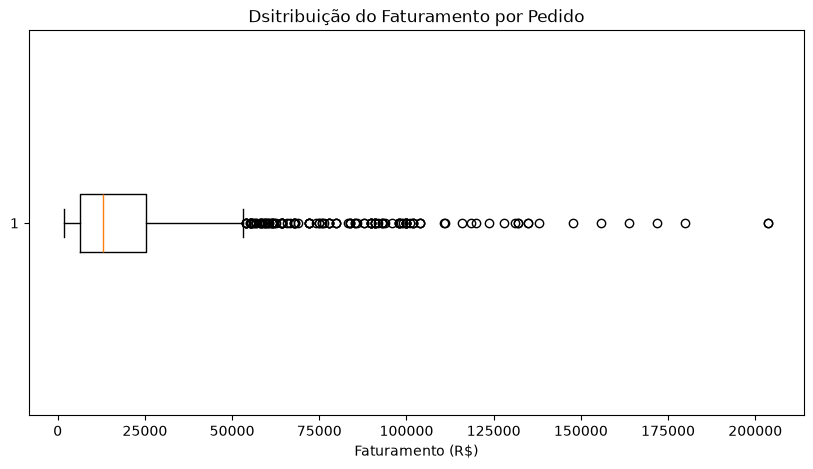

In [233]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.boxplot(
    df_analise_vendas['Faturamento Total'],
    vert=False
)

plt.title('Dsitribuição do Faturamento por Pedido')
plt.xlabel('Faturamento (R$)')

plt.show()

In [ ]:
# Evolução mensal do Faturamento
vendas_produtos = (df_analise_vendas['Mês']) = df_analise_vendas['Data Pedido'].dt.month

vendas_mensais = (
    df_analise_vendas.groupby('Mês')['Faturamento Total']
    .sum()
)

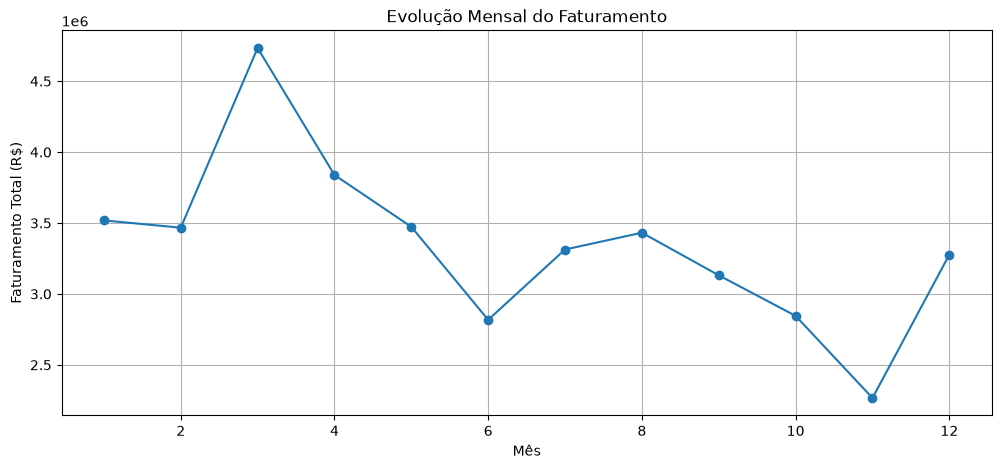

In [ ]:
# Mostrando evolução mensal do faturamento 
vendas_mensais.plot(
    kind='line',
    figsize=(12,5),
    marker='o'
)

plt.title('Evolução Mensal do Faturamento')
plt.xlabel('Mês')
plt.ylabel('Faturamento Total (R$)')
plt.grid()
plt.show()

In [251]:
# Desempenho dos produtos
faturamento_produtos = (
    df_analise_vendas.groupby('Produto')['Faturamento Total']
    .sum()
    .sort_values(ascending=False)
)
print(faturamento_produtos)

Produto
Bolsa       12859128.00
Mochila      7863397.38
Mala         7093989.09
Tênis        3672579.30
Carteira     3046260.00
Fone         2160015.00
Boné         1833837.09
Garrafa      1585139.10
Name: Faturamento Total, dtype: float64


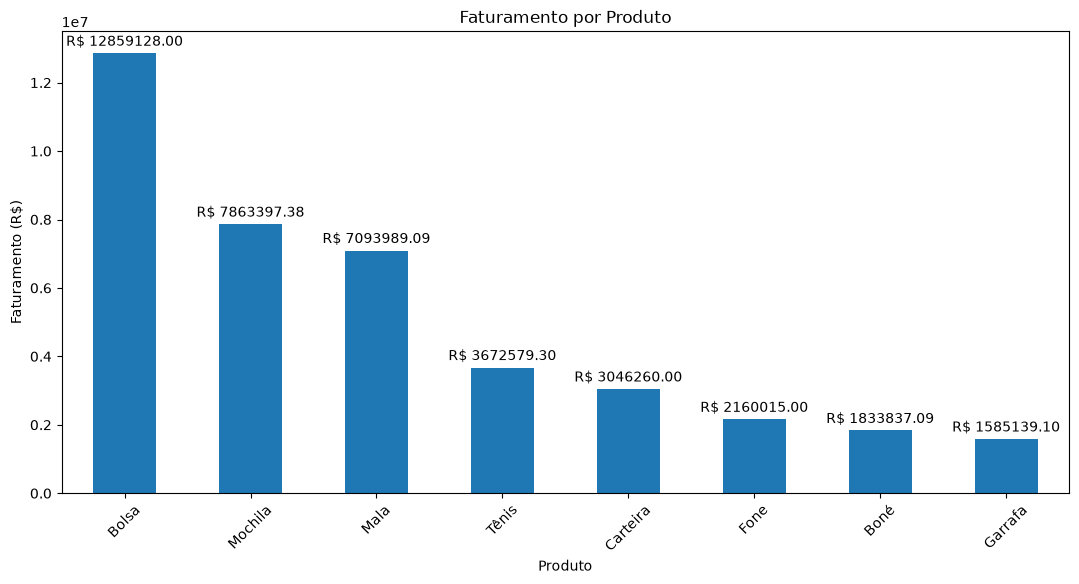

In [253]:
fig, ax = plt.subplots(figsize=(13, 6))

faturamento_produtos.plot(
    kind='bar'
)

# Inserindo os valores nas barras
ax.bar_label(
    ax.containers[0],
    fmt='R$ %.2f',
    padding=3
)

plt.title('Faturamento por Produto')
plt.xlabel('Produto')
plt.ylabel('Faturamento (R$)')
plt.xticks(rotation=45)

plt.show()

In [259]:
faturamento_lojas = (
    df_analise_vendas.groupby('Código Loja')['Faturamento Total']
    .sum()
    .sort_values(ascending=False)
)

print(faturamento_lojas)

Código Loja
Matriz SP       15990616.66
Filial 02 RJ    14063358.42
Filial 01 ES    10060369.88
Name: Faturamento Total, dtype: float64


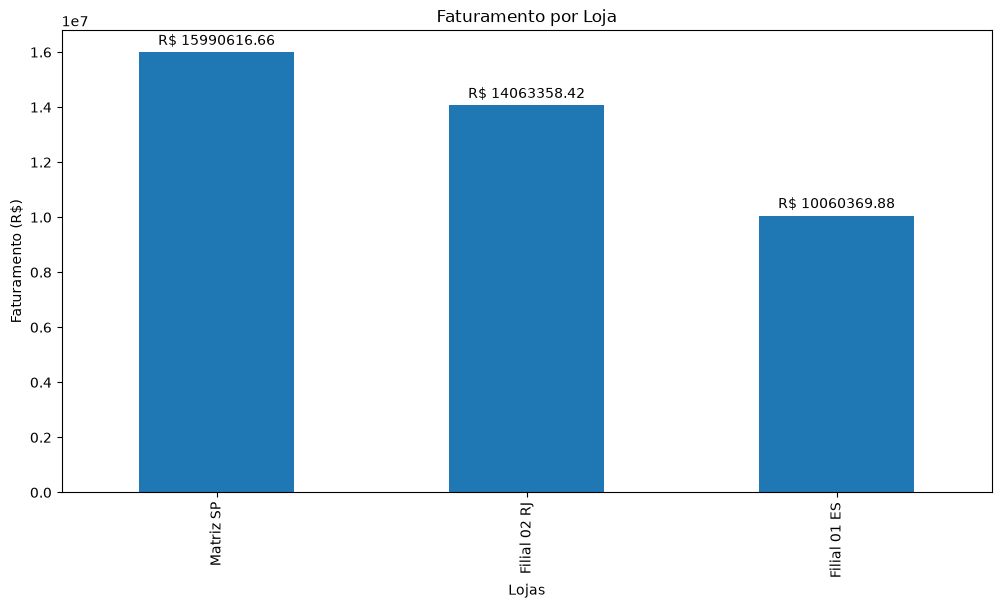

In [260]:
fig, ax = plt.subplots(figsize=(13, 6))

faturamento_lojas.plot(
    kind='bar',
    figsize=(12, 6)
)

# Inserindo os valores nas barras
ax.bar_label(
    ax.containers[0],
    fmt='R$ %.2f',
    padding=3
)

plt.title('Faturamento por Loja')
plt.xlabel('Lojas')
plt.ylabel('Faturamento (R$)')

plt.show()

In [ ]:
#Método de pagamento mais utilizado
metodo_pagamento = (
    df_analise_vendas.groupby('Pagamento')['Faturamento Total']
    .sum()
    .sort_values(ascending=False)

)

print(metodo_pagamento)

In [ ]:
#Visualizanção dos produtos mais vendidos por cada loja

produto_loja = (
    df_analise_vendas.groupby(['Código Loja', 'Produto'])['Faturamento Total']
    .sum()
    .reset_index()

)

produto_campeao = produto_loja.loc[
    produto_loja.groupby('Código Loja')['Faturamento Total'].idxmax()
]


print(produto_campeao)

     Código Loja Produto  Faturamento Total
0   Filial 01 ES   Bolsa          2982015.0
8   Filial 02 RJ   Bolsa          4482513.0
16     Matriz SP   Bolsa          5394600.0


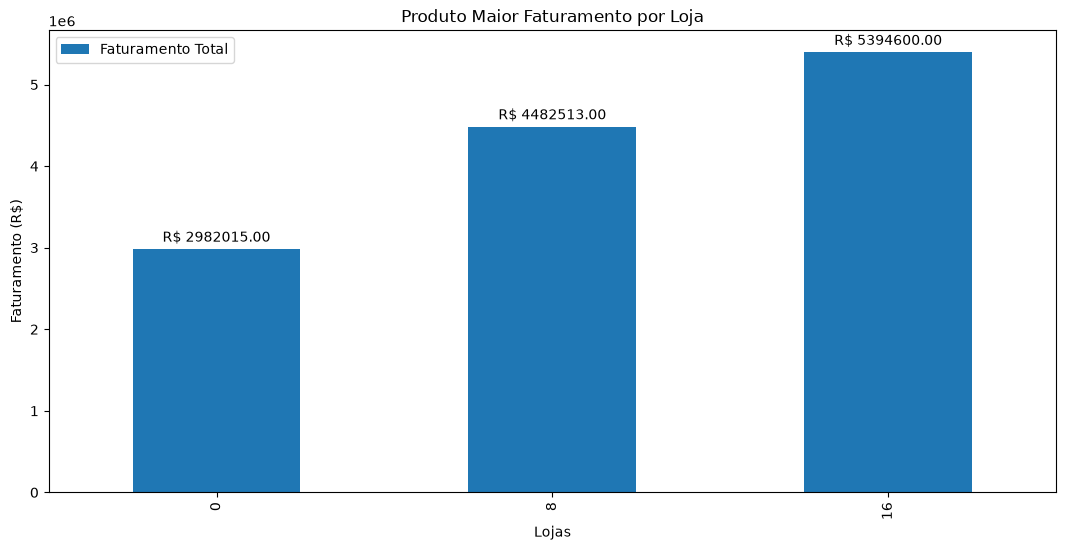

In [282]:
fig, ax = plt.subplots(figsize=(13, 6))

produto_campeao.plot(
    kind='bar',
    ax=ax

)


# Inserindo os valores nas barras
ax.bar_label(
    ax.containers[0],
    fmt='R$ %.2f',
    padding=3
)

plt.title('Produto Maior Faturamento por Loja')
plt.xlabel('Lojas')
plt.ylabel('Faturamento (R$)')

plt.show()

In [ ]:
#Identificação dos produtos mais vendidos por cada loja
#Aqui podemos analisar que os produtos mais vendidos por cada loja não deteem o maior faturamento.
vendas_loja = (df_vendas.groupby(['Código Loja', 'Produto'])['Quantidade'].sum().reset_index())

mais_vendidos = vendas_loja.loc[vendas_loja.groupby('Código Loja')['Quantidade'].idxmax('Código Loja')]

print(mais_vendidos)


     Código Loja   Produto  Quantidade
6   Filial 01 ES   Mochila        3769
10  Filial 02 RJ  Carteira        5497
21     Matriz SP      Mala        5750


In [264]:
#Faturamento por tipo de Pagamento
faturamento_por_pagamento = (
    df_vendas.groupby('Pagamento')['Faturamento Total'].sum().reset_index().sort_values('Faturamento Total', ascending=False)
    )

print(faturamento_por_pagamento)

           Pagamento  Faturamento Total
0  Cartão de Crédito        25284699.37
1  Transferência/PIX        14829645.59


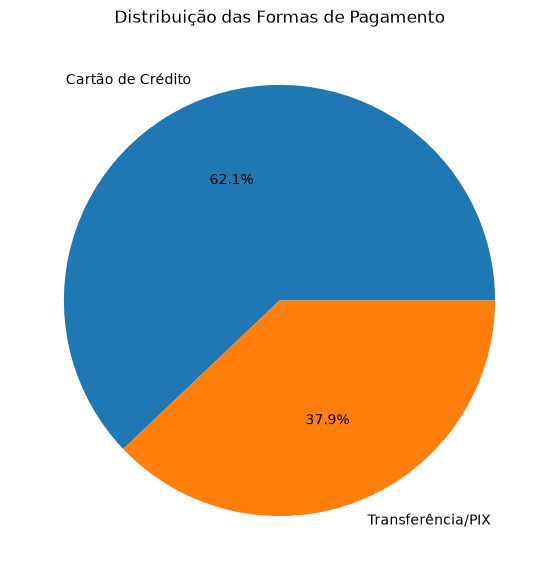

In [279]:
pagamentos = (
    df_analise_vendas['Pagamento']
    .value_counts()
)

pagamentos.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7, 7)
)

plt.title('Distribuição das Formas de Pagamento')

plt.ylabel('')

plt.show()

In [303]:
correlacao = df_analise_vendas[
    ['Quantidade', 'Preço Unitário', 'Faturamento Total']
].corr(method='pearson')

print(correlacao)

                   Quantidade  Preço Unitário  Faturamento Total
Quantidade           1.000000       -0.024985           0.598493
Preço Unitário      -0.024985        1.000000           0.649498
Faturamento Total    0.598493        0.649498           1.000000


In [301]:
# Existe diferença relevante no faturamento médio entre as lojas?
analise_lojas = (
    df_analise_vendas.groupby('Código Loja')['Faturamento Total']
    .agg(
        Media='mean',
        Mediana='median',
        Desvio_Padrao='std'
    )
)

print(analise_lojas)

                     Media  Mediana  Desvio_Padrao
Código Loja                                       
Filial 01 ES  13503.852188   9030.0   11026.967061
Filial 02 RJ  19505.351484  12600.0   20469.918756
Matriz SP     32700.647566  20352.0   32011.131925


In [324]:
# Total de pedidos de cada loja
total_pedidos_loja = (
    df_analise_vendas.groupby('Código Loja')['Quantidade']
    .sum()
    .sort_values(ascending=False)
)

print(total_pedidos_loja)

Código Loja
Matriz SP       41142
Filial 02 RJ    37195
Filial 01 ES    25447
Name: Quantidade, dtype: int64


In [307]:
analise_lojas['Coeficiente Variação Loja'] = (
    analise_lojas['Desvio_Padrao'] /
    analise_lojas['Media'] * 100
)

print(analise_lojas)

                     Media  Mediana  Desvio_Padrao  Coeficiente Variação Loja
Código Loja                                                                  
Filial 01 ES  13503.852188   9030.0   11026.967061                  81.657937
Filial 02 RJ  19505.351484  12600.0   20469.918756                 104.945142
Matriz SP     32700.647566  20352.0   32011.131925                  97.891431


In [328]:
pedidos_por_loja = (
    df_analise_vendas.groupby('Código Loja')['ID Pedido']
    .count()
    .sort_values(ascending=False)

)
print(pedidos_por_loja)    

Código Loja
Filial 01 ES    745
Filial 02 RJ    721
Matriz SP       489
Name: ID Pedido, dtype: int64


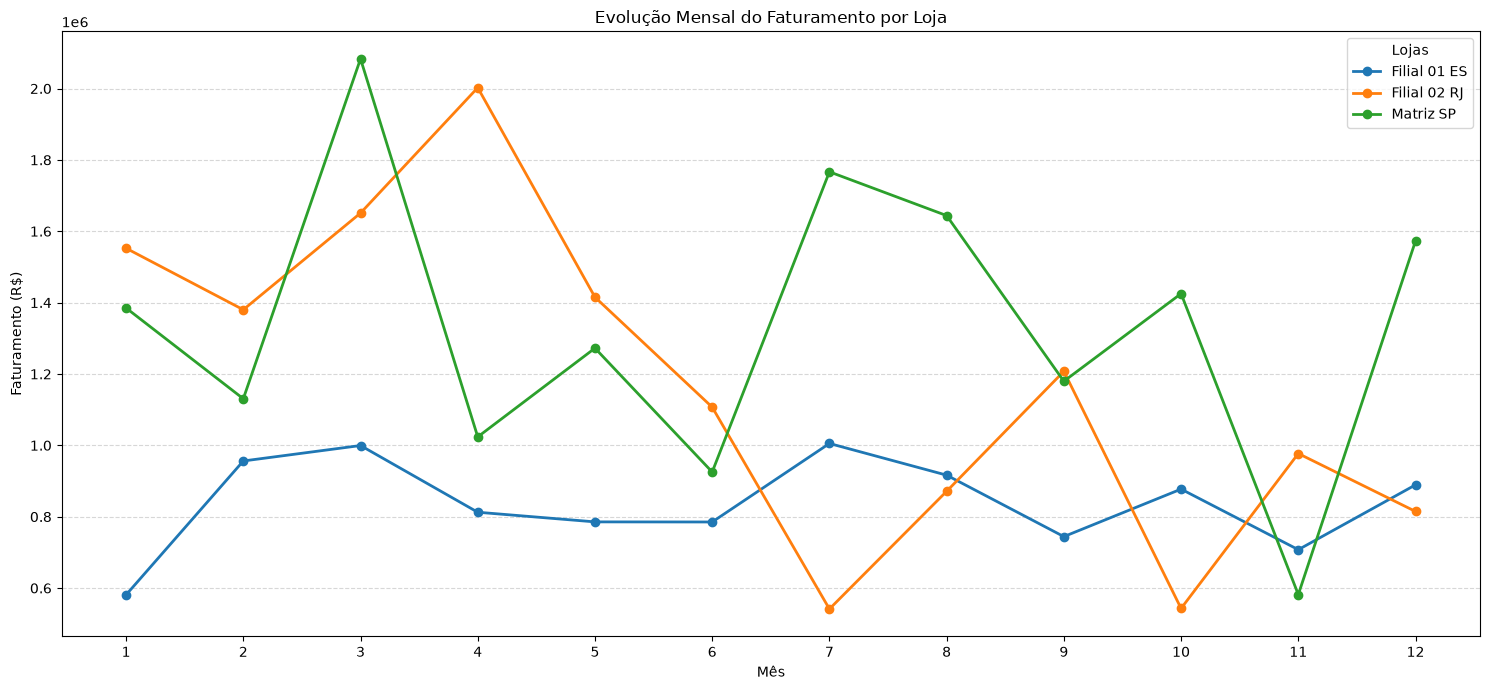

In [329]:
# Evolução mensal por cada loja
analise_mensal = (df_analise_vendas['Mês']) = df_analise_vendas['Data Pedido'].dt.month

analise_mensal_loja = (
    df_analise_vendas.groupby(['Código Loja', 'Mês'])['Faturamento Total']
    .sum()
    .unstack()
)

fig, ax = plt.subplots(figsize=(15, 7))

analise_mensal_loja.T.plot(
    kind='line',
    marker='o',
    linewidth=2,
    ax=ax
)

ax.set_title('Evolução Mensal do Faturamento por Loja')
ax.set_xlabel('Mês')
ax.set_ylabel('Faturamento (R$)')

ax.set_xticks(range(1, 13))

ax.legend(title='Lojas')
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [330]:
print(analise_mensal_loja.head())


Mês                   1           2           3           4           5   \
Código Loja                                                                
Filial 01 ES   581095.66   956220.83   999513.37   812563.78   785516.74   
Filial 02 RJ  1552396.83  1380135.57  1651037.03  2002490.87  1415326.80   
Matriz SP     1385000.44  1130648.14  2083280.66  1023748.92  1272411.86   

Mês                   6           7           8           9           10  \
Código Loja                                                                
Filial 01 ES   785235.08  1005267.40   916468.60   744252.24   877350.76   
Filial 02 RJ  1107053.22   541380.72   871227.79  1207561.45   542909.96   
Matriz SP      925303.92  1766661.39  1643973.16  1179630.78  1425213.45   

Mês                  11          12  
Código Loja                          
Filial 01 ES  707601.20   889284.22  
Filial 02 RJ  977080.66   814757.52  
Matriz SP     581835.32  1572908.62  


In [ ]:
#A A1500107 apresenta maior faturamento médio porque comercializa produtos de maior preço?
# O que esse indicador responde?
# Faturamento - Quanto cada produto faturou naquela loja?
# Quantidade - Quantas unidades daquele produto foram vendidas naquela loja?
# Preço médio - Qual foi o preço unitário médio praticado para aquele produto naquela loja?
analise_produto_loja = (
    df_analise_vendas.groupby(['Código Loja', 'Produto'])
    .agg(
        Faturamento_Total = ('Faturamento Total', 'sum'),
        Quantidade = ('Quantidade', 'sum'),
        Preco_Medio = ('Preço Unitário', 'mean')
    )
)


print(analise_produto_loja)

                       Faturamento_Total  Quantidade  Preco_Medio
Código Loja  Produto                                             
Filial 01 ES Bolsa            2982015.00        2985       999.00
             Boné              432580.13        2687       160.99
             Carteira          691110.00        3291       210.00
             Fone              567948.00        3572       159.00
             Garrafa           340840.10        2857       119.30
             Mala             1826536.21        3659       499.19
             Mochila          2378201.31        3769       630.99
             Tênis             841139.13        2627       320.19
Filial 02 RJ Bolsa            4482513.00        4487       999.00
             Boné              622709.32        3868       160.99
             Carteira         1154370.00        5497       210.00
             Fone              738396.00        4644       159.00
             Garrafa           644100.70        5399       119.30
          

In [ ]:
# A bolsa é o produto campeão de vendas das três lojas.
# A Matriz localizada no estado de São Paulo, lidera o ranking com maior número de vendas.
# Automaticamente possui o maior faturamento desse mesmo produto. 
